<a href="https://colab.research.google.com/github/imrenga/ScoutingPASS/blob/main/RengaRamachandran_AI_powered_EHR_Assistant_Low_code_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Problem Statement**

## Business Context

A healthcare provider network offers a patient portal for accessing EHR data (labs, medications, visit summaries, imaging impressions, discharge instructions). Patients frequently misunderstand clinical terminology and next steps, driving high volumes of portal messages and call-center contacts, reduced adherence, and dissatisfaction. Patients also search online, encountering misinformation that may conflict with their records.

However, a patient-facing AI layer introduces non-trivial risks:
- misinterpretation of outputs as medical advice
- unsafe self-management behaviors
- inequities from varying health literacy, and
- PHI exposure through new interfaces and integrations.

The organization therefore needs a patient education and navigation assistant that is clinically safe-by-design, privacy-preserving, and auditable, with clear boundaries and escalation to clinicians.

## Objective

The objective is to build a POC in the form of a guardrailed, patient-facing AI education and navigation assistant powered by a single-agent system within the patient portal that:
- explains selected parts of the patient's record in plain language,
- answers general medical questions using vetted sources with citations, and
- enforces safety constraints (no diagnosis, no medication changes, no urgent-care triage beyond 'seek immediate care')

The end goal is to scale and expose this POC as an assistant to the patients to reduce avoidable support contacts and improve comprehension/adherence.

## Data Dictionary

**1) SQLite database (clinical operational data)**  
Use SQLite to represent a portal/EHR backend. Keep the dataset small (e.g., 5-20 patients, 50-200 lab rows, 20-50 medications, 10-30 encounters) while maintaining realistic clinical fields.

**Table: patients**  
**Purpose:** patient identity and personalization (minimize PHI).  
**Key attributes:**
- patient_id (PK)
- first_name
- last_name (optional)
- dob (or birth_year for de-identification)
- sex_at_birth (optional)
- preferred_language (e.g., en, es)
- health_literacy_level (e.g., basic, intermediate)
- timezone
- created_at  

**Table: encounters**  
**Purpose:** encounter context and visit details.  
**Key attributes:**
- encounter_id (PK)
- patient_id (FK)
- encounter_date
- encounter_type (e.g., primary_care, ED, telehealth)
- reason_for_visit (short text)
- diagnosis_summary (short text)
- provider_specialty
- followup_instructions (text)
- care_team_contact (text or phone placeholder)

**Table: clinical_notes**  
**Purpose:** free-text clinical documentation associated with encounters.  
**Key attributes:**
- note_id (PK)
- encounter_id (FK)
- patient_id (FK)
- note_type (e.g., visit_note, discharge_summary)
- note_text (text)
- author_role (e.g., physician, nurse)
- created_at  

**Table: labs**  
**Purpose:** laboratory results with reference ranges and interpretation flags.  
**Key attributes:**
- lab_result_id (PK)
- patient_id (FK)
- ordered_date
- result_date
- loinc_code (optional)
- test_name (e.g., “Hemoglobin A1c”)
- value_numeric (nullable)
- value_text (nullable; e.g., “Negative”)
- unit
- ref_range_low
- ref_range_high
- flag (e.g., low, high, normal, abnormal)
- lab_source (e.g., “Quest”, “In-house”)  

**Table: medications**  
**Purpose:** medication list and prescribing details.  
**Key attributes:**
- med_id (PK)
- patient_id (FK)
- rxnorm_code (optional)
- med_name (e.g., “Metformin”)
- dose (e.g., “500 mg”)
- route (e.g., oral)
- frequency (e.g., “twice daily”)
- start_date
- end_date (nullable)
- status (e.g., active, stopped)
- indication (optional)
- prescriber_specialty

**Table: allergies**  
**Purpose:** allergy and adverse reaction history.  
**Key attributes:**
- allergy_id (PK)
- patient_id (FK)
- substance
- reaction (text)
- severity (e.g., mild, severe)
- recorded_date

---

**2) CSV files (reference content + mappings + policies)**  
CSV files for curated reference content, mappings, and policy rules.

**CSV: trusted_sources_catalog.csv**  
**Purpose:** catalog of approved sources and citation metadata.  
**Columns:**
- source_id
- source_name
- base_url
- content_type (guideline, patient_education)
- license_notes
- is_allowed (true/false)

**CSV: patient_friendly_lab_explanations.csv**  
**Purpose:** plain-language explanations for common lab tests.  
**Columns:**
- test_name_normalized
- plain_language_summary (2-4 sentences)
- why_it_matters
- common_reasons_high (high-level, non-diagnostic)
- common_reasons_low
- when_to_contact_clinician (general guidance)
- source_id / citation_url

**CSV: medication_education.csv**  
**Purpose:** medication education content.  
**Columns:**
- med_name_normalized
- drug_class
- what_it_is_for (general)
- common_side_effects
- serious_side_effects_red_flags
- interaction_warnings_general
- citation_url

**CSV: safety_policy_rules.csv**  
**Purpose:** safety rules and escalation/refusal triggers.  
**Columns:**
- rule_id
- rule_type (refusal / escalation / allowed)
- pattern_or_topic (e.g., “stop medication”, “dose change”, “chest pain”)
- action (refuse, escalate_emergency, escalate_clinician, provide_education_only)
- standard_response_template

# **Please read the instructions carefully before starting the project.**

This is a commented Python Notebook file in which all the instructions and tasks to be performed are mentioned.

* Blanks '\_\_\_\_\_' are provided in the notebook that
needs to be filled with an appropriate code to get the correct result. With every '\_\_\_\_\_' blank, there is a comment that briefly describes what needs to be filled in the blank space.
* Identify the task to be performed correctly, and only then proceed to write the required code.
* Please sequentially run the code cells from the beginning to avoid any unnecessary errors.
* Add the results/observations derived from the analysis in the presentation and submit the same. Any mathematical or computational details that are a graded part of the project can be included in the Appendix section of the presentation.

# **Installing and Importing Necessary Libraries and Dependencies**

In [ ]:
!pip install -q \
  langgraph==0.2.39 \
  langchain==0.3.14 \
  langchain-core==0.3.29 \
  langchain-community==0.3.14 \
  langsmith==0.1.147 \
  openai==1.59.6 \
  langchain-openai==0.2.14 \
  pydantic==2.10.4 \
  pandas==2.2.3 \
  numpy==2.2.1

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for VSCode/Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [ ]:
import os              # environment variables / runtime config
import re              # text normalization + lightweight pattern matching
import json            # serialize/parse tool outputs + structured data interchange
import sqlite3         # connect/query the SQLite database
import pandas as pd    # load/query CSV reference data
import numpy as np     # numeric utilities
from typing import Any, Dict, List, Optional, TypedDict, Tuple  # type hints + structured state for agent workflow

from langchain_core.messages import SystemMessage, HumanMessage, BaseMessage, ToolMessage  # chat + tool observation messages
from langchain_core.prompts import ChatPromptTemplate  # consistent prompt templates
from langchain_core.tools import tool                 # define LLM-callable tools
from langchain_core.output_parsers import JsonOutputParser  # parse LLM outputs into JSON

from langchain_openai import ChatOpenAI  # OpenAI chat model wrapper

from langgraph.graph import StateGraph, END  # build the LangGraph state machine + termination node

from IPython.display import Image, display  # visualize the graph / notebook-friendly display

# **Data Loading and Model Initialization**

## Data Loading

We first define the paths to the SQLite database and CSV files.

In [ ]:
DB_PATH = "/content/health_portal.db"    # complete the code to add the path to the SQLite database file
CSV_TRUSTED_SOURCES = "/content/trusted_sources_catalog.csv"    # complete the code to add the path to the trusted_sources_catalog.csv file
CSV_LAB_EXPLAIN =  "/content/patient_friendly_lab_explanations.csv"    # complete the code to add the path to the patient_friendly_lab_explanations.csv file
CSV_MED_EDU =  "/content/medication_education.csv"    # complete the code to add the path to the medication_education.csv file
CSV_POLICY =  "/content/safety_policy_rules.csv"    # complete the code to add the path to the safety_policy_rules.csv file

Next, we load the CSV files.

In [ ]:
import pandas as pd

trusted_sources_df = pd.read_csv(CSV_TRUSTED_SOURCES)
lab_explain_df     = pd.read_csv(CSV_LAB_EXPLAIN)
med_edu_df         = pd.read_csv(CSV_MED_EDU)
policy_rules_df    = pd.read_csv(CSV_POLICY)

Let's do a quick check of the number of records in each CSV file.

In [ ]:
print("trusted_sources rows:", len(trusted_sources_df))
print("lab explanations rows:", len(lab_explain_df))
print("med education rows:", len(med_edu_df))
print("policy rules rows:", len(policy_rules_df))

trusted_sources rows: 20
lab explanations rows: 30
med education rows: 30
policy rules rows: 10


Next, we
- load the SQLite database,
- print the tables present in it, and
- check the number of records in each table

In [ ]:
import sqlite3

con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row  # nicer dict-like rows
cur = con.cursor()

# List tables
tables = cur.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name").fetchall()
print("Tables:", [t["name"] for t in tables])

# Check row counts
for t in ["patients","encounters","clinical_notes","labs","medications","allergies"]:
    c = cur.execute(f"SELECT COUNT(*) AS n FROM {t}").fetchone()["n"]
    print(f"{t:15s} {c}")

Tables: ['allergies', 'clinical_notes', 'encounters', 'labs', 'medications', 'patients']
patients        10
encounters      29
clinical_notes  43
labs            141
medications     56
allergies       15


## Model Initialization

We first extract the required credentials from the `config.json` file.

In [ ]:
# Load the credentials JSON file and extract values
import json
import os

file_name = 'config.json'
with open(file_name, 'r') as file:
    config = json.load(file)
    # Extract nested credentials from the 'openai' key
    openai_config = config.get("openai", {})
    OPENAI_API_KEY = openai_config.get("OPENAI_API_KEY")

# Store API credentials in environment variables
os.environ['OPENAI_API_KEY'] = OPENAI_API_KEY
# Clear any custom base URL to use the standard OpenAI API endpoint
if "OPENAI_BASE_URL" in os.environ:
    del os.environ["OPENAI_BASE_URL"]

In [ ]:
from langchain_openai import ChatOpenAI

try:
    # Initialize a basic client to test the connectivity with standard default base URL
    test_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.0)
    response = test_llm.invoke("Say 'OpenAI connection is successful!'")
    print("SUCCESS! Response from OpenAI:", response.content)
except Exception as e:
    print("CONNECTION FAILED:", e)

SUCCESS! Response from OpenAI: OpenAI connection is successful!


Next, we set up the LLMs.
- We set up separate LLM instances for output generation and output validation.

In [ ]:
from langchain_openai import ChatOpenAI

# Define the generator model
GEN_MODEL = "gpt-4o-mini"

# Define the validator model
VAL_MODEL = "gpt-4o-mini"

# Initialize the generator LLM instance
llm_gen = ChatOpenAI(
    model=GEN_MODEL,
    temperature=0.0
)

# Initialize the validator LLM instance
llm_val = ChatOpenAI(
    model=VAL_MODEL,
    temperature=0.0
)

# **Defining Tools**

## Utility Functions

We define small utility functions to standardize common operations

- querying SQLite,
- normalizing user text for reliable matching, and
- serializing outputs to JSON

, so that the agent's tools and nodes remain consistent, less error-prone, and easier to debug

In [ ]:
def sql_query(q: str, params: tuple = ()):
    """Execute a parameterized SQL query on the SQLite cursor and return rows as dictionaries.

    Inputs:
        q (str): SQL query string (use ? placeholders for parameters).
        params (tuple): Parameters to bind to the query placeholders.

    Output:
        List[Dict[str, Any]]: Query results where each row is converted to a dict
        (column_name -> value). Returns an empty list if no rows match.
    """
    rows = cur.execute(q, params).fetchall()  # run query + fetch all result rows
    return [dict(r) for r in rows]            # convert sqlite3.Row objects to plain dicts

In [ ]:
def norm_text(s: str) -> str:
    """Normalize text for consistent matching (lowercase + trimmed + whitespace-collapsed).

    Inputs:
        s (str): Any input text (will be cast to string).

    Output:
        str: Normalized text with:
            - leading/trailing whitespace removed
            - converted to lowercase
            - internal whitespace collapsed to single spaces
    """
    return re.sub(r"\s+", " ", str(s).strip().lower())  # standardize spacing/case for comparisons

In [ ]:
from typing import Any
import json

def to_json(obj: Any) -> str:
    """Convert a Python object into a JSON string safely.

    Inputs:
        obj (Any): Any Python object (dict/list/str/etc.). If the object contains
            non-JSON-serializable values (e.g., datetime, numpy types), they are
            converted to strings via default=str.

    Output:
        str: JSON-formatted string (UTF-8 friendly, ensure_ascii=False).
    """
    return json.dumps(obj, ensure_ascii=False, default=str)  # robust serialization for tool outputs/logging

## Tools

Now, we define all the tools we want the single-agent system to have access to.

### **`get_patient_profile`**

Fetches a patient's basic demographic and preference profile from the `patients` table.

In [ ]:
@tool("get_patient_profile")
def get_patient_profile(patient_id: str) -> str:
    """
    Retrieve a patient's basic profile from the SQLite `patients` table for personalization.

    Args:
        patient_id (str): Unique patient identifier (e.g., "P001") used to look up the patient record.

    Returns:
        str: A JSON string containing the patient profile fields:
             patient_id, first_name, last_name, birth_year, sex_at_birth,
             preferred_language, health_literacy_level, timezone, created_at.
             If the patient is not found, returns a JSON string like:
             {"error": "Patient <patient_id> not found"}.
    """
    rows = sql_query("""
        SELECT patient_id, first_name, last_name, birth_year, sex_at_birth,
               preferred_language, health_literacy_level, timezone, created_at
        FROM patients
        WHERE patient_id = ?
    """, (patient_id,))
    return to_json(rows[0] if rows else {"error": f"Patient {patient_id} not found"})

### **`list_patient_encounters`**

Retrieves the most recent encounter records for a patient from the `encounters` table.

In [ ]:
@tool("list_patient_encounters")
def list_patient_encounters(patient_id: str, limit: int = 5) -> str:
    """
    Fetch a patient's most recent encounters from the SQLite `encounters` table.

    This tool is used to provide visit context (e.g., last appointment type, reason for visit,
    follow-up instructions) for summarization and navigation-style answers.

    Args:
        patient_id (str): Unique patient identifier (e.g., "P003").
        limit (int, optional): Maximum number of encounters to return. For safety and
            consistency, this value can be capped (between 3-7). Defaults to 5.

    Returns:
        str: A JSON string containing a list of encounter objects, each including:
             encounter_id, encounter_date, encounter_type, reason_for_visit, diagnosis_summary,
             provider_specialty, followup_instructions, care_team_contact.
             Returns "[]" (JSON empty list) if no encounters are found.
    """
    max_val = 7    # defined maximum number of encounters to return
    try:
        limit = max(1, min(int(limit), max_val))
    except Exception:
        limit = max_val

    rows = sql_query("""
        SELECT encounter_id, encounter_date, encounter_type, reason_for_visit,
               diagnosis_summary, provider_specialty, followup_instructions, care_team_contact
        FROM encounters
        WHERE patient_id = ?
        ORDER BY encounter_date DESC
        LIMIT ?
    """, (patient_id, limit))
    return to_json(rows)

### **`get_recent_clinical_note`**

Returns the latest clinical note (visit note or discharge summary) for a patient from the `clinical_notes` table.

In [ ]:
@tool("get_recent_clinical_note")
def get_recent_clinical_note(patient_id: str, note_type: str = "visit_note") -> str:
    """
    Retrieve the most recent clinical note for a patient from the SQLite `clinical_notes` table.

    This tool supports note summarization and “what happened at my last visit?” questions by
    pulling the latest note text for a specified note category.

    Args:
        patient_id (str): Unique patient identifier (e.g., "P007").
        note_type (str, optional): Type of note to retrieve. Allowed values are:
            - "visit_note"
            - "discharge_summary"
            Any other value is defaulted to "visit_note".

    Returns:
        str: A JSON string containing a single note object with fields:
             note_id, encounter_id, patient_id, note_type, note_text, created_at, author_role.
             If no matching note exists, returns a JSON string like:
             {"error": "No <note_type> found for patient <patient_id>"}.
    """
    if note_type not in ("visit_note", "discharge_summary"):
        note_type = "visit_note"

    rows = sql_query("""
        SELECT note_id, encounter_id, patient_id, note_type, note_text, created_at, author_role
        FROM clinical_notes
        WHERE patient_id = ? AND note_type = ?
        ORDER BY created_at DESC
        LIMIT 1
    """, (patient_id, note_type))
    return to_json(rows[0] if rows else {"error": f"No {note_type} found for patient {patient_id}"})

### **`get_clinical_notes_for_encounter`**

Fetches all clinical notes associated with a specific encounter ID from the `clinical_notes` table.

In [ ]:
@tool("get_clinical_notes_for_encounter")
def get_clinical_notes_for_encounter(encounter_id: str) -> str:
    """
    Retrieve all clinical notes linked to a specific encounter from the SQLite `clinical_notes` table.

    This tool is useful when the agent first identifies the relevant encounter (e.g., the most recent
    visit from `list_patient_encounters`) and then needs to fetch all associated note types (visit note,
    discharge summary) for a complete, encounter-scoped summary.

    Args:
        encounter_id (str): Unique encounter identifier to fetch notes for.

    Returns:
        str: A JSON string containing a list of note objects. Each note includes:
             note_id, encounter_id, patient_id, note_type, note_text, created_at, author_role.
             Returns "[]" (JSON empty list) if no notes are found for the encounter.
    """
    rows = sql_query("""
        SELECT note_id, encounter_id, patient_id, note_type, note_text, created_at, author_role
        FROM clinical_notes
        WHERE encounter_id = ?
        ORDER BY created_at ASC
    """, (encounter_id,))
    return to_json(rows)

### **`get_labs`**

Retrieves recent lab results for a patient (optionally filtered by a specific test name) from the `labs` table.

In [ ]:
@tool("get_labs")
def get_labs(patient_id: str, test_name: Optional[str] = None, limit: int = 10) -> str:
    """
    Fetch recent laboratory results for a patient from the SQLite `labs` table.

    This tool supports lab-explanation use cases by retrieving the most recent lab records,
    optionally filtered to a specific lab test name (case-insensitive exact match).

    Args:
        patient_id (str): Unique patient identifier (e.g., "P004").
        test_name (Optional[str], optional): If provided, restricts results to rows where
            `test_name` matches (case-insensitive). If None, returns a mix of recent labs.
        limit (int, optional): Maximum number of rows to return. For safety and prompt
            size control, the value can be capped (between 7-10). Defaults to 10.

    Returns:
        str: A JSON string containing a list of lab result objects, each including:
             lab_result_id, ordered_date, result_date, loinc_code, test_name, value_numeric,
             value_text, unit, ref_range_low, ref_range_high, flag, lab_source.
             Returns "[]" (JSON empty list) if no results are found.
    """
    max_val = 10    # defined maximum number of rows to return
    try:
        limit = max(1, min(int(limit), max_val))
    except Exception:
        limit = max_val

    if test_name:
        rows = sql_query("""
            SELECT lab_result_id, ordered_date, result_date, loinc_code, test_name,
                   value_numeric, value_text, unit, ref_range_low, ref_range_high, flag, lab_source
            FROM labs
            WHERE patient_id = ? AND lower(test_name) = lower(?)
            ORDER BY result_date DESC
            LIMIT ?
        """, (patient_id, test_name, limit))
    else:
        rows = sql_query("""
            SELECT lab_result_id, ordered_date, result_date, loinc_code, test_name,
                   value_numeric, value_text, unit, ref_range_low, ref_range_high, flag, lab_source
            FROM labs
            WHERE patient_id = ?
            ORDER BY result_date DESC
            LIMIT ?
        """, (patient_id, limit))

    return to_json(rows)

### **`get_medications`**

Retrieves a patient's medication list filtered by status (active/stopped/all) from the `medications` table.

In [ ]:
@tool("get_medications")
def get_medications(patient_id: str, status: str = "active") -> str:
    """
    Retrieve a patient's medication list from the SQLite `medications` table.

    This tool supports medication education and reconciliation-style questions by returning
    the patient's recorded medications along with basic directions (dose/route/frequency),
    status (active/stopped), and a high-level indication when available.

    Args:
        patient_id (str): Unique patient identifier (e.g., "P002").
        status (str, optional): Filter for medication status:
            - "active": only active meds
            - "stopped": only stopped meds
            - "all": both active and stopped
            Any other value defaults to "active".

    Returns:
        str: A JSON string containing a list of medication objects, each including:
             med_id, rxnorm_code, med_name, dose, route, frequency, start_date, end_date,
             status, indication, prescriber_specialty.
             Returns "[]" (JSON empty list) if no medications match the filter.
    """
    if status not in ("active", "stopped", "all"):
        status = "active"

    if status == "all":
        rows = sql_query("""
            SELECT med_id, rxnorm_code, med_name, dose, route, frequency,
                   start_date, end_date, status, indication, prescriber_specialty
            FROM medications
            WHERE patient_id = ?
            ORDER BY status DESC, start_date DESC
        """, (patient_id,))
    else:
        rows = sql_query("""
            SELECT med_id, rxnorm_code, med_name, dose, route, frequency,
                   start_date, end_date, status, indication, prescriber_specialty
            FROM medications
            WHERE patient_id = ? AND status = ?
            ORDER BY start_date DESC
        """, (patient_id, status))

    return to_json(rows)

### **`get_allergies`**

Retrieves a patient's recorded allergies from the `allergies` table.

In [ ]:
@tool("get_allergies")
def get_allergies(patient_id: str) -> str:
    """
    Retrieve a patient's recorded allergies from the SQLite `allergies` table.

    This tool supports safety-aware responses (e.g., antibiotic/allergy concerns) by returning
    the substances, reactions, and severity recorded in the patient record.

    Args:
        patient_id (str): Unique patient identifier (e.g., "P005").

    Returns:
        str: A JSON string containing a list of allergy objects, each including:
             allergy_id, substance, reaction, severity, recorded_date.
             Returns "[]" (JSON empty list) if no allergies are recorded for the patient.
    """
    rows = sql_query("""
        SELECT allergy_id, substance, reaction, severity, recorded_date
        FROM allergies
        WHERE patient_id = ?
        ORDER BY recorded_date DESC
    """, (patient_id,))
    return to_json(rows)

### **`lookup_lab_education`**

Looks up plain-language explanations and guidance for a lab test from the `patient_friendly_lab_explanations` CSV.

In [ ]:
@tool("lookup_lab_education")
def lookup_lab_education(test_name: str) -> str:
    """
    Retrieve patient-friendly education content for a lab test from `patient_friendly_lab_explanations.csv`.

    This tool provides plain-language explanations and safe guidance for a lab test, along with
    citation metadata (e.g., citation_url and source_id) that the agent can reference to ground
    general medical information.

    Args:
        test_name (str): Lab test name to look up (e.g., "Hemoglobin A1c"). Matching is done using
            a normalized exact match first, then a fallback substring match.

    Returns:
        str: A JSON string containing the education row fields (e.g., test_name_normalized,
             plain_language_summary, why_it_matters, common_reasons_high/low, when_to_contact_clinician,
             citation_url, source_id). If no match is found, returns:
             {"error": "No lab education found for '<test_name>'"}.
    """
    tn = norm_text(test_name)
    df = lab_explain_df.copy()
    df["_k"] = df["test_name_normalized"].astype(str).map(norm_text)

    hit = df[df["_k"] == tn]
    if hit.empty:
        hit = df[df["_k"].str.contains(tn, na=False)]

    if hit.empty:
        return to_json({"error": f"No lab education found for '{test_name}'"})

    row = hit.iloc[0].drop(labels=["_k"]).to_dict()
    return to_json(row)

### **`lookup_medication_education`**

Looks up plain-language medication education (uses, side effects, red flags) from the `medication_education` CSV.

In [ ]:
@tool("lookup_medication_education")
def lookup_medication_education(med_name: str) -> str:
    """
    Retrieve patient-friendly education content for a medication from `medication_education.csv`.

    This tool provides general medication education (what it is for, common/serious side effects,
    general interaction warnings) plus citation metadata (citation_url, source_id) to support
    grounded, non-prescriptive answers.

    Args:
        med_name (str): Medication name to look up (e.g., "Metformin"). Matching is done using
            a normalized exact match first, then a fallback substring match.

    Returns:
        str: A JSON string containing the education row fields (e.g., med_name_normalized,
             drug_class, what_it_is_for, common_side_effects, serious_side_effects_red_flags,
             interaction_warnings_general, citation_url, source_id). If no match is found, returns:
             {"error": "No medication education found for '<med_name>'"}.
    """
    mn = norm_text(med_name)
    df = med_edu_df.copy()
    df["_k"] = df["med_name_normalized"].astype(str).map(norm_text)

    hit = df[df["_k"] == mn]
    if hit.empty:
        hit = df[df["_k"].str.contains(mn, na=False)]

    if hit.empty:
        return to_json({"error": f"No medication education found for '{med_name}'"})

    row = hit.iloc[0].drop(labels=["_k"]).to_dict()
    return to_json(row)

### **`lookup_trusted_source`**

Retrieves metadata for a trusted medical source (name, URL, type) from the `trusted_sources_catalog` CSV.

In [ ]:
@tool("lookup_trusted_source")
def lookup_trusted_source(source_id: str) -> str:
    """
    Retrieve metadata for an approved medical information source from `trusted_sources_catalog.csv`.

    This tool supports citation grounding by mapping a `source_id` (stored in lab/med education rows)
    to a human-readable source name and URL.

    Args:
        source_id (str): Identifier for the trusted source (e.g., "S01").

    Returns:
        str: A JSON string containing the source metadata fields (e.g., source_id, source_name,
             base_url, content_type, license_notes, is_allowed). If the source_id is not found,
             returns: {"error": "source_id <source_id> not found"}.
    """
    hit = trusted_sources_df[trusted_sources_df["source_id"] == source_id]
    if hit.empty:
        return to_json({"error": f"source_id {source_id} not found"})
    return to_json(hit.iloc[0].to_dict())

### **`policy_route`**

Applies safety policy rules to a user query to decide whether to answer, refuse, or escalate.

In [ ]:
@tool("policy_route")
def policy_route(user_text: str) -> str:
    """
    Apply safety guardrails to a user query using `safety_policy_rules.csv` and return a routing decision.

    This tool implements a lightweight, deterministic policy layer that helps the agent decide whether to:
    - answer normally ("answer"),
    - refuse unsafe requests such as diagnosis/dose changes ("refuse"),
    - escalate urgent symptom descriptions ("escalate_emergency" or "escalate_clinician").

    Matching approach (MVP):
    - Normalizes the user text and checks whether each rule's `pattern_or_topic` appears as a substring.
    - If multiple rules match, selects the highest-priority action using:
      escalate_emergency > escalate_clinician > refuse > answer.

    Args:
        user_text (str): The raw user input/query to evaluate.

    Returns:
        str: A JSON string with keys:
            - action: "answer" | "refuse" | "escalate_emergency" | "escalate_clinician"
            - rule_id: matched rule identifier (if any)
            - template: standard response template for refusal/escalation (if any)
            - matched_rules: list of all matched rules with their actions/topics
        If no rules match, returns:
            {"action": "answer", "matched_rules": []}
    """
    text = norm_text(user_text)
    rules = policy_rules_df.to_dict(orient="records")

    matches = []
    for r in rules:
        topic = norm_text(r.get("pattern_or_topic", ""))
        if topic and topic in text:
            matches.append(r)

    priority = {"escalate_emergency": 3, "escalate_clinician": 2, "refuse": 1, "answer": 0}

    if not matches:
        return to_json({"action": "answer", "matched_rules": []})

    matches_sorted = sorted(
        matches,
        key=lambda r: priority.get(r.get("agent_action", "answer"), 0),
        reverse=True
    )
    best = matches_sorted[0]

    out = {
        "action": best["agent_action"],
        "rule_id": best["rule_id"],
        "template": best["standard_response_template"],
        "matched_rules": [
            {"rule_id": m["rule_id"], "action": m["agent_action"], "topic": m["pattern_or_topic"]}
            for m in matches_sorted
        ]
    }
    return to_json(out)

# **Defining the Agent**

We now define the single-agent system using LangGraph.

## Agent State

We start by defining the state of the agent.

- **`AgentState`** is the structured data container that LangGraph nodes read from and write to, carrying the user query, safety routing decisions, ReAct messages/tool observations, and the final response for a single run.

In [ ]:
class AgentState(TypedDict):
    """
    LangGraph state schema for a single-turn, tool-using (ReAct) patient-records explainer.

    Holds the request context (patient_id, user_query), deterministic safety routing outputs
    (decision/policy_template), within-run ReAct message history (including ToolMessages),
    loop control (step/max_steps), optional citations, the drafted/final answer, and errors.
    """
    patient_id: str
    user_query: str

    decision: str
    policy_rule_id: Optional[str]
    policy_template: Optional[str]

    messages: List[BaseMessage]
    step: int
    max_steps: int

    citations: List[Dict[str, Any]]
    draft_answer: Optional[str]
    final_answer: Optional[str]

    errors: List[str]

REACT_SYSTEM_PROMPT = """You are a safe, compassionate, and helpful patient-facing clinical education and navigation AI assistant.
Your role is to help patients understand their EHR data (such as lab results, medications, and clinical notes) in plain language, and answer general medical questions using vetted clinical resources.

### CRITICAL SAFETY RULES:
1. NEVER diagnose the patient or suggest specific disease conditions they might have.
2. NEVER recommend changing, stopping, starting, or adjusting medication dosages.
3. ALWAYS refer patients to their prescribing doctor or primary care team for clinical decisions or personalized advice.
4. If a patient expresses urgent, life-threatening symptoms (e.g., chest pain, shortness of breath, sudden weakness), immediately instruct them to seek emergency care (911 or the nearest ER).

### WORKING GUIDELINES:
- Use the provided tools (e.g., lookup_lab_education, lookup_medication_education, lookup_trusted_source) to ground your answers with validated clinical details.
- Cite your sources by name and provide the citation URL where appropriate.
- Keep your tone supportive, objective, clear, and easy to understand (around a 6th to 8th-grade reading level).
- Only retrieve information relevant to the patient's identity provided in the context.
"""

In [ ]:
REACT_SYSTEM_PROMPT = """You are a safe, compassionate, and helpful patient-facing clinical education and navigation AI assistant.
Your role is to help patients understand their EHR data (such as lab results, medications, and clinical notes) in plain language, and answer general medical questions using vetted clinical resources.

### CRITICAL SAFETY RULES:
1. NEVER diagnose the patient or suggest specific disease conditions they might have.
2. NEVER recommend changing, stopping, starting, or adjusting medication dosages.
3. ALWAYS refer patients to their prescribing doctor or primary care team for clinical decisions or personalized advice.
4. If a patient expresses urgent, life-threatening symptoms (e.g., chest pain, shortness of breath, sudden weakness), immediately instruct them to seek emergency care (911 or the nearest ER).

### WORKING GUIDELINES:
- Use the provided tools (e.g., lookup_lab_education, lookup_medication_education, lookup_trusted_source) to ground your answers with validated clinical details.
- Cite your sources by name and provide the citation URL where appropriate.
- Keep your tone supportive, objective, clear, and easy to understand (around a 6th to 8th-grade reading level).
- Only retrieve information relevant to the patient's identity provided in the context.
"""

Next, we create the initial LangGraph state for one ReAct run.

- **`init_state`** initializes the starting AgentState for a single ReAct run, including the user query, safety defaults, seeded messages, step limits, and empty placeholders for outputs/errors.

In [ ]:
# Re-define or ensure init_state handles AgentState
def init_state(patient_id: str, user_query: str, max_steps: int = 5) -> Dict[str, Any]:
    return {
        "patient_id": patient_id,
        "user_query": user_query,

        "decision": "answer",
        "policy_rule_id": None,
        "policy_template": None,

        "messages": [
            SystemMessage(content=REACT_SYSTEM_PROMPT),
            HumanMessage(content=f"patient_id={patient_id}\nUser question: {user_query}")
        ],
        "step": 0,
        "max_steps": max_steps,

        "citations": [],
        "draft_answer": None,
        "final_answer": None,
        "errors": [],
    }

## Agent Nodes

We'll now define the nodes for the LangGraph workflow.

# Re-define tool functions to resolve NameError dependency issues caused by skipped cells
@tool("get_patient_profile")
def get_patient_profile(patient_id: str) -> str:
    """Retrieve basic profile from the SQLite patients table."""
    rows = sql_query("SELECT * FROM patients WHERE patient_id = ?", (patient_id,))
    return to_json(rows[0] if rows else {"error": f"Patient {patient_id} not found"})

@tool("list_patient_encounters")
def list_patient_encounters(patient_id: str, limit: int = 5) -> str:
    """Fetch recent encounters from the encounters table."""
    rows = sql_query("SELECT * FROM encounters WHERE patient_id = ? ORDER BY encounter_date DESC LIMIT ?", (patient_id, limit))
    return to_json(rows)

@tool("get_recent_clinical_note")
def get_recent_clinical_note(patient_id: str, note_type: str = "visit_note") -> str:
    """Retrieve the most recent clinical note."""
    rows = sql_query("SELECT * FROM clinical_notes WHERE patient_id = ? AND note_type = ? ORDER BY created_at DESC LIMIT 1", (patient_id, note_type))
    return to_json(rows[0] if rows else {"error": f"No {note_type} found for patient {patient_id}"})

@tool("get_clinical_notes_for_encounter")
def get_clinical_notes_for_encounter(encounter_id: str) -> str:
    """Retrieve clinical notes for an encounter."""
    rows = sql_query("SELECT * FROM clinical_notes WHERE encounter_id = ? ORDER BY created_at ASC", (encounter_id,))
    return to_json(rows)

@tool("get_labs")
def get_labs(patient_id: str, test_name: Optional[str] = None, limit: int = 10) -> str:
    """Retrieve recent laboratory results."""
    if test_name:
        rows = sql_query("SELECT * FROM labs WHERE patient_id = ? AND lower(test_name) = lower(?) ORDER BY result_date DESC LIMIT ?", (patient_id, test_name, limit))
    else:
        rows = sql_query("SELECT * FROM labs WHERE patient_id = ? ORDER BY result_date DESC LIMIT ?", (patient_id, limit))
    return to_json(rows)

@tool("get_medications")
def get_medications(patient_id: str, status: str = "active") -> str:
    """Retrieve patient medications."""
    if status == "all":
        rows = sql_query("SELECT * FROM medications WHERE patient_id = ? ORDER BY status DESC, start_date DESC", (patient_id,))
    else:
        rows = sql_query("SELECT * FROM medications WHERE patient_id = ? AND status = ? ORDER BY start_date DESC", (patient_id, status))
    return to_json(rows)

@tool("get_allergies")
def get_allergies(patient_id: str) -> str:
    """Retrieve patient allergies."""
    rows = sql_query("SELECT * FROM allergies WHERE patient_id = ? ORDER BY recorded_date DESC", (patient_id,))
    return to_json(rows)

@tool("lookup_lab_education")
def lookup_lab_education(test_name: str) -> str:
    """Lookup lab education from CSV."""
    tn = norm_text(test_name)
    df = lab_explain_df.copy()
    df["_k"] = df["test_name_normalized"].astype(str).map(norm_text)
    hit = df[df["_k"] == tn]
    if hit.empty:
        hit = df[df["_k"].str.contains(tn, na=False)]
    if hit.empty:
        return to_json({"error": f"No lab education found for '{test_name}'"})
    return to_json(hit.iloc[0].drop(labels=["_k"]).to_dict())

@tool("lookup_medication_education")
def lookup_medication_education(med_name: str) -> str:
    """Lookup medication education from CSV."""
    mn = norm_text(med_name)
    df = med_edu_df.copy()
    df["_k"] = df["med_name_normalized"].astype(str).map(norm_text)
    hit = df[df["_k"] == mn]
    if hit.empty:
        hit = df[df["_k"].str.contains(mn, na=False)]
    if hit.empty:
        return to_json({"error": f"No medication education found for '{med_name}'"})
    return to_json(hit.iloc[0].drop(labels=["_k"]).to_dict())

@tool("lookup_trusted_source")
def lookup_trusted_source(source_id: str) -> str:
    """Lookup trusted source from CSV."""
    hit = trusted_sources_df[trusted_sources_df["source_id"] == source_id]
    if hit.empty:
        return to_json({"error": f"source_id {source_id} not found"})
    return to_json(hit.iloc[0].to_dict())

@tool("policy_route")
def policy_route(user_text: str) -> str:
    """Run policy engine rules from CSV."""
    text = norm_text(user_text)
    rules = policy_rules_df.to_dict(orient="records")
    matches = []
    for r in rules:
        topic = norm_text(r.get("pattern_or_topic", ""))
        if topic and topic in text:
            matches.append(r)
    priority = {"escalate_emergency": 3, "escalate_clinician": 2, "refuse": 1, "answer": 0}
    if not matches:
        return to_json({"action": "answer", "matched_rules": []})
    matches_sorted = sorted(matches, key=lambda r: priority.get(r.get("agent_action", "answer"), 0), reverse=True)
    best = matches_sorted[0]
    return to_json({
        "action": best["agent_action"],
        "rule_id": best["rule_id"],
        "template": best["standard_response_template"],
        "matched_rules": [{"rule_id": m["rule_id"], "action": m["agent_action"], "topic": m["pattern_or_topic"]} for m in matches_sorted]
    })

# Create list of tools
TOOLS = [
    get_patient_profile,
    list_patient_encounters,
    get_recent_clinical_note,
    get_clinical_notes_for_encounter,
    get_labs,
    get_medications,
    get_allergies,
    lookup_lab_education,
    lookup_medication_education,
    lookup_trusted_source,
]

# Enable LLM tool-calling
llm_gen_tools = llm_gen.bind_tools(TOOLS)

In [ ]:
# Re-define tool functions to resolve NameError dependency issues caused by skipped cells
@tool("get_patient_profile")
def get_patient_profile(patient_id: str) -> str:
    """Retrieve basic profile from the SQLite patients table."""
    rows = sql_query("SELECT * FROM patients WHERE patient_id = ?", (patient_id,))
    return to_json(rows[0] if rows else {"error": f"Patient {patient_id} not found"})

@tool("list_patient_encounters")
def list_patient_encounters(patient_id: str, limit: int = 5) -> str:
    """Fetch recent encounters from the encounters table."""
    rows = sql_query("SELECT * FROM encounters WHERE patient_id = ? ORDER BY encounter_date DESC LIMIT ?", (patient_id, limit))
    return to_json(rows)

@tool("get_recent_clinical_note")
def get_recent_clinical_note(patient_id: str, note_type: str = "visit_note") -> str:
    """Retrieve the most recent clinical note."""
    rows = sql_query("SELECT * FROM clinical_notes WHERE patient_id = ? AND note_type = ? ORDER BY created_at DESC LIMIT 1", (patient_id, note_type))
    return to_json(rows[0] if rows else {"error": f"No {note_type} found for patient {patient_id}"})

@tool("get_clinical_notes_for_encounter")
def get_clinical_notes_for_encounter(encounter_id: str) -> str:
    """Retrieve clinical notes for an encounter."""
    rows = sql_query("SELECT * FROM clinical_notes WHERE encounter_id = ? ORDER BY created_at ASC", (encounter_id,))
    return to_json(rows)

@tool("get_labs")
def get_labs(patient_id: str, test_name: Optional[str] = None, limit: int = 10) -> str:
    """Retrieve recent laboratory results."""
    if test_name:
        rows = sql_query("SELECT * FROM labs WHERE patient_id = ? AND lower(test_name) = lower(?) ORDER BY result_date DESC LIMIT ?", (patient_id, test_name, limit))
    else:
        rows = sql_query("SELECT * FROM labs WHERE patient_id = ? ORDER BY result_date DESC LIMIT ?", (patient_id, limit))
    return to_json(rows)

@tool("get_medications")
def get_medications(patient_id: str, status: str = "active") -> str:
    """Retrieve patient medications."""
    if status == "all":
        rows = sql_query("SELECT * FROM medications WHERE patient_id = ? ORDER BY status DESC, start_date DESC", (patient_id,))
    else:
        rows = sql_query("SELECT * FROM medications WHERE patient_id = ? AND status = ? ORDER BY start_date DESC", (patient_id, status))
    return to_json(rows)

@tool("get_allergies")
def get_allergies(patient_id: str) -> str:
    """Retrieve patient allergies."""
    rows = sql_query("SELECT * FROM allergies WHERE patient_id = ? ORDER BY recorded_date DESC", (patient_id,))
    return to_json(rows)

@tool("lookup_lab_education")
def lookup_lab_education(test_name: str) -> str:
    """Lookup lab education from CSV."""
    tn = norm_text(test_name)
    df = lab_explain_df.copy()
    df["_k"] = df["test_name_normalized"].astype(str).map(norm_text)
    hit = df[df["_k"] == tn]
    if hit.empty:
        hit = df[df["_k"].str.contains(tn, na=False)]
    if hit.empty:
        return to_json({"error": f"No lab education found for '{test_name}'"})
    return to_json(hit.iloc[0].drop(labels=["_k"]).to_dict())

@tool("lookup_medication_education")
def lookup_medication_education(med_name: str) -> str:
    """Lookup medication education from CSV."""
    mn = norm_text(med_name)
    df = med_edu_df.copy()
    df["_k"] = df["med_name_normalized"].astype(str).map(norm_text)
    hit = df[df["_k"] == mn]
    if hit.empty:
        hit = df[df["_k"].str.contains(mn, na=False)]
    if hit.empty:
        return to_json({"error": f"No medication education found for '{med_name}'"})
    return to_json(hit.iloc[0].drop(labels=["_k"]).to_dict())

@tool("lookup_trusted_source")
def lookup_trusted_source(source_id: str) -> str:
    """Lookup trusted source from CSV."""
    hit = trusted_sources_df[trusted_sources_df["source_id"] == source_id]
    if hit.empty:
        return to_json({"error": f"source_id {source_id} not found"})
    return to_json(hit.iloc[0].to_dict())

@tool("policy_route")
def policy_route(user_text: str) -> str:
    """Run policy engine rules from CSV."""
    text = norm_text(user_text)
    rules = policy_rules_df.to_dict(orient="records")
    matches = []
    for r in rules:
        topic = norm_text(r.get("pattern_or_topic", ""))
        if topic and topic in text:
            matches.append(r)
    priority = {"escalate_emergency": 3, "escalate_clinician": 2, "refuse": 1, "answer": 0}
    if not matches:
        return to_json({"action": "answer", "matched_rules": []})
    matches_sorted = sorted(matches, key=lambda r: priority.get(r.get("agent_action", "answer"), 0), reverse=True)
    best = matches_sorted[0]
    return to_json({
        "action": best["agent_action"],
        "rule_id": best["rule_id"],
        "template": best["standard_response_template"],
        "matched_rules": [{"rule_id": m["rule_id"], "action": m["agent_action"], "topic": m["pattern_or_topic"]} for m in matches_sorted]
    })

# Create list of tools
TOOLS = [
    get_patient_profile,
    list_patient_encounters,
    get_recent_clinical_note,
    get_clinical_notes_for_encounter,
    get_labs,
    get_medications,
    get_allergies,
    lookup_lab_education,
    lookup_medication_education,
    lookup_trusted_source,
]

# Enable LLM tool-calling
llm_gen_tools = llm_gen.bind_tools(TOOLS)

### **`policy_gate_node`**

Applies deterministic safety rules to the user query to decide whether to answer, refuse, or escalate before the ReAct loop proceeds.

In [ ]:
def policy_gate_node(state: AgentState) -> Dict[str, Any]:
    """
    Run the deterministic policy router on the user's query and write the resulting safety decision into state.

    Inputs:
        state (AgentState): Current graph state containing at least `user_query` (and existing `errors` if any).

    Outputs:
        Dict[str, Any]: State updates including:
          - decision: "answer" | "refuse" | "escalate_emergency" | "escalate_clinician"
          - policy_rule_id: matched rule id (or None)
          - policy_template: standardized refusal/escalation message (or None)
        On failure, returns an update to `errors` with a descriptive message.
    """
    try:
        route = json.loads(policy_route.invoke({"user_text": state["user_query"]}))
        return {
            "decision": route.get("action", "answer"),
            "policy_rule_id": route.get("rule_id"),
            "policy_template": route.get("template"),
        }
    except Exception as e:
        return {"errors": state.get("errors", []) + [f"policy_gate failed: {e}"]}

### **`agent_node`**

Invokes the tool-enabled LLM to either request tool calls (continue ReAct loop) or produce a draft final response, while enforcing emergency short-circuit and max-step stopping.

In [ ]:
def agent_node(state: AgentState) -> Dict[str, Any]:
    """
    Run one ReAct "agent" step using the tool-bound LLM.

    The node:
    - short-circuits for emergency escalation by emitting a draft answer from the policy template,
    - enforces a max-step hard stop to prevent infinite tool loops,
    - otherwise calls the LLM with the current message history and appends the AI message.

    Inputs:
        state (AgentState): Current state containing `messages`, `step`, `max_steps`, and policy fields.

    Outputs:
        Dict[str, Any]: State updates that always include `messages` and `step`, and optionally:
          - `draft_answer` when the LLM returns a final text response (no tool calls) or when hard-stopped.
        If the LLM returns tool calls, this node does not set `draft_answer`, allowing the graph to route
        to the tool execution node.
    """
    # Emergency short-circuit: finalize will enforce template; still produce a draft to stop loop
    if state.get("decision") == "escalate_emergency" and state.get("policy_template"):
        return {
            "draft_answer": state["policy_template"],
            "messages": state["messages"],  # still write something explicit
            "step": state["step"],
        }

    # Hard-stop
    if state["step"] >= state["max_steps"]:
        forced = (
            "I may not have enough information yet to answer confidently. "
            "I can explain what your records show or share general information. "
            "For medical advice (especially medication changes) or urgent concerns, please contact your clinician."
        )
        return {
            "draft_answer": forced,
            "messages": state["messages"],
            "step": state["step"],
        }

    # Invoke LLM with tools
    ai_msg = llm_gen_tools.invoke(state["messages"])

    # Explicitly build updated messages + step (no in-place mutation reliance)
    new_messages = list(state["messages"]) + [ai_msg]
    new_step = state["step"] + 1

    # If no tool calls, treat as draft answer and stop looping
    if not getattr(ai_msg, "tool_calls", None):
        return {
            "messages": new_messages,
            "step": new_step,
            "draft_answer": ai_msg.content,
        }

    # Tool calls exist: continue loop, but MUST still return an update
    return {
        "messages": new_messages,
        "step": new_step,
    }

### **`tool_exec_node`**

Executes the LLM-requested tool calls safely (patient-scoped enforcement + limit caps), appends tool outputs as `ToolMessages`, and collects citations/errors for the run.

In [ ]:
# tools that must be forced to use the logged-in patient_id (prevents cross-patient access)
PATIENT_SCOPED_TOOLNAMES = {
    "get_patient_profile",
    "list_patient_encounters",
    "get_recent_clinical_note",
    "get_labs",
    "get_medications",
    "get_allergies",
}

In [ ]:
def _cap_limit(args: Dict[str, Any], max_limit: int = 10) -> Dict[str, Any]:
    """
    Cap a tool call's 'limit' argument to control data volume and prompt size.

    Args:
        args (Dict[str, Any]): Tool argument dictionary (may include a 'limit' key).
        max_limit (int, optional): Maximum allowed limit value. Defaults to 10.

    Returns:
        Dict[str, Any]: A copied args dictionary with 'limit' coerced to int and capped to max_limit
        when present; otherwise returns args unchanged.
    """
    out = dict(args)  # copy args so we don't mutate the original dict
    if "limit" in out and out["limit"] is not None:
        try:
            out["limit"] = min(int(out["limit"]), max_limit)  # cap numeric limit
        except Exception:
            out["limit"] = max_limit  # fallback if limit isn't parseable
    return out

In [ ]:
def tool_exec_node(state: AgentState) -> Dict[str, Any]:
    """
    Execute tool calls produced by the tool-enabled LLM and append results back into the message trace.

    This node:
    - reads tool calls from the last AI message,
    - enforces patient scoping by overwriting patient_id for sensitive tools,
    - caps limit parameters for controlled retrieval,
    - executes each tool from the approved tool map,
    - appends each tool output as a ToolMessage observation,
    - optionally extracts citations from lab/med education tool outputs.

    Inputs:
        state (AgentState): Current state containing at least:
            - patient_id: used to enforce patient scoping
            - messages: last message may contain tool_calls
            - citations/errors: existing lists to extend

    Outputs:
        Dict[str, Any]: State updates containing:
            - messages: updated message list including ToolMessages (tool observations)
            - citations: updated list with extracted citation metadata (if any)
            - errors: updated list with any tool execution / blocking errors
    """
    last = state["messages"][-1]  # last AI message should contain tool_calls
    tool_calls = getattr(last, "tool_calls", []) or []  # tool call specs from LLM
    tool_map = {t.name: t for t in TOOLS}  # whitelist: tool name -> tool callable

    new_messages = list(state["messages"])                 # copy messages (avoid in-place mutation)
    new_citations = list(state.get("citations", []))       # copy citations
    new_errors = list(state.get("errors", []))             # copy errors

    for tc in tool_calls:
        name = tc.get("name")
        args = tc.get("args", {}) or {}
        tool_id = tc.get("id")  # required so ToolMessage can be associated to the correct call

        # Block any tool not in our allowlist (security)
        if name not in tool_map:
            new_errors.append(f"Blocked unknown tool call: {name}")
            new_messages.append(
                ToolMessage(content=f"Blocked unknown tool: {name}", name=name or "unknown", tool_call_id=tool_id)
            )
            continue

        # Critical: prevent cross-patient data access by enforcing patient_id
        if name in PATIENT_SCOPED_TOOLNAMES:
            args["patient_id"] = state["patient_id"]

        # Cap retrieval volume (limits prompt size and reduces accidental overexposure)
        if name in {"get_labs", "list_patient_encounters"}:
            args = _cap_limit(args, max_limit=10)

        try:
            # Execute tool (returns JSON string in our implementation)
            result_str = tool_map[name].invoke(args)
            if not isinstance(result_str, str):
                result_str = json.dumps(result_str, ensure_ascii=False, default=str)

            # Optional: extract citation metadata from education tools
            if name in {"lookup_lab_education", "lookup_medication_education"}:
                try:
                    data = json.loads(result_str)
                    if isinstance(data, dict) and "error" not in data:
                        cit = {
                            "source_id": data.get("source_id"),
                            "citation_url": data.get("citation_url"),
                            "used_for": "lab education" if name == "lookup_lab_education" else "med education",
                        }
                        if cit.get("source_id") or cit.get("citation_url"):
                            new_citations.append(cit)
                except Exception:
                    pass  # if parsing fails, skip citation extraction silently (MVP-friendly)

            # Append tool observation for the agent to use in the next step (ReAct "Observation")
            new_messages.append(ToolMessage(content=result_str, name=name, tool_call_id=tool_id))

        except Exception as e:
            err = f"{name} failed: {e}"
            new_errors.append(err)
            new_messages.append(ToolMessage(content=err, name=name, tool_call_id=tool_id))

    return {
        "messages": new_messages,
        "citations": new_citations,
        "errors": new_errors,
    }  # explicit updates required by LangGraph

### **`should_continue`**

Decides whether the graph should execute tools, call the agent again, or end with the final response based on the current state.

In [ ]:
def should_continue(state: AgentState) -> str:
    """
    Determine the next step in the ReAct loop based on the latest state.

    Inputs:
        state (AgentState): Current state containing:
          - draft_answer (optional): set when the agent has produced a final response
          - messages: includes the most recent AI message which may contain tool_calls

    Returns:
        str: The next node label for LangGraph routing:
          - "final" if a draft_answer exists (stop looping and finalize)
          - "tool" if the last AI message contains tool_calls (execute tools next)
          - "agent" otherwise (continue by calling the agent again)
    """
    if state.get("draft_answer"):
        return "final"  # agent has produced an answer; exit loop

    last = state["messages"][-1]  # inspect the most recent AI message
    if getattr(last, "tool_calls", None):
        return "tool"  # tools requested; execute them

    return "agent"  # no answer yet and no tools requested; ask agent again

### **`final_policy_override_node`**

Enforces refusal/escalation templates as the final answer when required; otherwise returns the agent’s drafted answer.

In [ ]:
def final_policy_override_node(state: AgentState) -> Dict[str, Any]:
    """
    Apply the final, deterministic safety override to select the response returned to the user.

    Inputs:
        state (AgentState): Current state containing:
          - decision: policy decision (answer/refuse/escalate_*)
          - policy_template: standardized refusal/escalation message (if applicable)
          - draft_answer: agent-generated answer (if applicable)

    Outputs:
        Dict[str, Any]: State update with:
          - final_answer: the policy template if decision requires it; otherwise the draft_answer,
            or a conservative fallback if no draft exists.
    """
    decision = state.get("decision", "answer")
    template = state.get("policy_template")

    # If policy requires refusal/escalation, override any LLM output
    if decision in ("escalate_emergency", "refuse", "escalate_clinician") and template:
        return {"final_answer": template}

    # Otherwise return the model's draft answer (or a fallback)
    return {"final_answer": state.get("draft_answer") or "I’m not sure how to answer that yet."}

## Agent Workflow

We now define the LangGraph workflow.

In [ ]:
from langgraph.graph import StateGraph, END
from typing import Dict, Any, List, Optional, TypedDict
from langchain_core.messages import BaseMessage, ToolMessage
from langchain_core.tools import tool
import json
import re

# Define PATIENT_SCOPED_TOOLNAMES explicitly in this scope
PATIENT_SCOPED_TOOLNAMES = {
    "get_patient_profile",
    "list_patient_encounters",
    "get_recent_clinical_note",
    "get_labs",
    "get_medications",
    "get_allergies",
}

def _cap_limit(args: Dict[str, Any], max_limit: int = 10) -> Dict[str, Any]:
    out = dict(args)
    if "limit" in out and out["limit"] is not None:
        try:
            out["limit"] = min(int(out["limit"]), max_limit)
        except Exception:
            out["limit"] = max_limit
    return out

# Explicitly define or re-declare tools in this cell to ensure they exist in local scope
@tool("get_patient_profile")
def get_patient_profile(patient_id: str) -> str:
    """Retrieve basic profile from the SQLite patients table."""
    rows = sql_query("SELECT * FROM patients WHERE patient_id = ?", (patient_id,))
    return to_json(rows[0] if rows else {"error": f"Patient {patient_id} not found"})

@tool("list_patient_encounters")
def list_patient_encounters(patient_id: str, limit: int = 5) -> str:
    """Fetch recent encounters from the encounters table."""
    rows = sql_query("SELECT * FROM encounters WHERE patient_id = ? ORDER BY encounter_date DESC LIMIT ?", (patient_id, limit))
    return to_json(rows)

@tool("get_recent_clinical_note")
def get_recent_clinical_note(patient_id: str, note_type: str = "visit_note") -> str:
    """Retrieve the most recent clinical note."""
    rows = sql_query("SELECT * FROM clinical_notes WHERE patient_id = ? AND note_type = ? ORDER BY created_at DESC LIMIT 1", (patient_id, note_type))
    return to_json(rows[0] if rows else {"error": f"No {note_type} found for patient {patient_id}"})

@tool("get_clinical_notes_for_encounter")
def get_clinical_notes_for_encounter(encounter_id: str) -> str:
    """Retrieve clinical notes for an encounter."""
    rows = sql_query("SELECT * FROM clinical_notes WHERE encounter_id = ? ORDER BY created_at ASC", (encounter_id,))
    return to_json(rows)

@tool("get_labs")
def get_labs(patient_id: str, test_name: Optional[str] = None, limit: int = 10) -> str:
    """Retrieve recent laboratory results."""
    if test_name:
        rows = sql_query("SELECT * FROM labs WHERE patient_id = ? AND lower(test_name) = lower(?) ORDER BY result_date DESC LIMIT ?", (patient_id, test_name, limit))
    else:
        rows = sql_query("SELECT * FROM labs WHERE patient_id = ? ORDER BY result_date DESC LIMIT ?", (patient_id, limit))
    return to_json(rows)

@tool("get_medications")
def get_medications(patient_id: str, status: str = "active") -> str:
    """Retrieve patient medications."""
    if status == "all":
        rows = sql_query("SELECT * FROM medications WHERE patient_id = ? ORDER BY status DESC, start_date DESC", (patient_id,))
    else:
        rows = sql_query("SELECT * FROM medications WHERE patient_id = ? AND status = ? ORDER BY start_date DESC", (patient_id, status))
    return to_json(rows)

@tool("get_allergies")
def get_allergies(patient_id: str) -> str:
    """Retrieve patient allergies."""
    rows = sql_query("SELECT * FROM allergies WHERE patient_id = ? ORDER BY recorded_date DESC", (patient_id,))
    return to_json(rows)

@tool("lookup_lab_education")
def lookup_lab_education(test_name: str) -> str:
    """Lookup lab education from CSV."""
    tn = norm_text(test_name)
    df = lab_explain_df.copy()
    df["_k"] = df["test_name_normalized"].astype(str).map(norm_text)
    hit = df[df["_k"] == tn]
    if hit.empty:
        hit = df[df["_k"].str.contains(tn, na=False)]
    if hit.empty:
        return to_json({"error": f"No lab education found for '{test_name}'"})
    return to_json(hit.iloc[0].drop(labels=["_k"]).to_dict())

@tool("lookup_medication_education")
def lookup_medication_education(med_name: str) -> str:
    """Lookup medication education from CSV."""
    mn = norm_text(med_name)
    df = med_edu_df.copy()
    df["_k"] = df["med_name_normalized"].astype(str).map(norm_text)
    hit = df[df["_k"] == mn]
    if hit.empty:
        hit = df[df["_k"].str.contains(mn, na=False)]
    if hit.empty:
        return to_json({"error": f"No medication education found for '{med_name}'"})
    return to_json(hit.iloc[0].drop(labels=["_k"]).to_dict())

@tool("lookup_trusted_source")
def lookup_trusted_source(source_id: str) -> str:
    """Lookup trusted source from CSV."""
    hit = trusted_sources_df[trusted_sources_df["source_id"] == source_id]
    if hit.empty:
        return to_json({"error": f"source_id {source_id} not found"})
    return to_json(hit.iloc[0].to_dict())

# Create list of tools
TOOLS = [
    get_patient_profile,
    list_patient_encounters,
    get_recent_clinical_note,
    get_clinical_notes_for_encounter,
    get_labs,
    get_medications,
    get_allergies,
    lookup_lab_education,
    lookup_medication_education,
    lookup_trusted_source,
]

# Re-bind tools to guarantee llm_gen_tools is defined globally
llm_gen_tools = llm_gen.bind_tools(TOOLS)

# Define AgentState
class AgentState(TypedDict):
    patient_id: str
    user_query: str
    decision: str
    policy_rule_id: Optional[str]
    policy_template: Optional[str]
    messages: List[BaseMessage]
    step: int
    max_steps: int
    citations: List[Dict[str, Any]]
    draft_answer: Optional[str]
    final_answer: Optional[str]
    errors: List[str]

# Ensure policy_gate_node is defined
def policy_gate_node(state: AgentState) -> Dict[str, Any]:
    try:
        route = json.loads(policy_route.invoke({"user_text": state["user_query"]}))
        return {
            "decision": route.get("action", "answer"),
            "policy_rule_id": route.get("rule_id"),
            "policy_template": route.get("template"),
        }
    except Exception as e:
        return {"errors": state.get("errors", []) + [f"policy_gate failed: {e}"]}

# Ensure agent_node is defined using global llm_gen_tools
def agent_node(state: AgentState) -> Dict[str, Any]:
    if state.get("decision") == "escalate_emergency" and state.get("policy_template"):
        return {
            "draft_answer": state["policy_template"],
            "messages": state["messages"],
            "step": state["step"],
        }

    if state["step"] >= state["max_steps"]:
        forced = (
            "I may not have enough information yet to answer confidently. "
            "I can explain what your records show or share general information. "
            "For medical advice (especially medication changes) or urgent concerns, please contact your clinician."
        )
        return {
            "draft_answer": forced,
            "messages": state["messages"],
            "step": state["step"],
        }

    ai_msg = llm_gen_tools.invoke(state["messages"])
    new_messages = list(state["messages"]) + [ai_msg]
    new_step = state["step"] + 1

    if not getattr(ai_msg, "tool_calls", None):
        return {
            "messages": new_messages,
            "step": new_step,
            "draft_answer": ai_msg.content,
        }

    return {
        "messages": new_messages,
        "step": new_step,
    }

# Ensure tool_exec_node is defined
def tool_exec_node(state: AgentState) -> Dict[str, Any]:
    last = state["messages"][-1]
    tool_calls = getattr(last, "tool_calls", []) or []
    tool_map = {t.name: t for t in TOOLS}

    new_messages = list(state["messages"])
    new_citations = list(state.get("citations", []))
    new_errors = list(state.get("errors", []))

    for tc in tool_calls:
        name = tc.get("name")
        args = tc.get("args", {}) or {}
        tool_id = tc.get("id")

        if name not in tool_map:
            new_errors.append(f"Blocked unknown tool call: {name}")
            new_messages.append(
                ToolMessage(content=f"Blocked unknown tool: {name}", name=name or "unknown", tool_call_id=tool_id)
            )
            continue

        if name in PATIENT_SCOPED_TOOLNAMES:
            args["patient_id"] = state["patient_id"]

        if name in {"get_labs", "list_patient_encounters"}:
            args = _cap_limit(args, max_limit=10)

        try:
            result_str = tool_map[name].invoke(args)
            if not isinstance(result_str, str):
                result_str = json.dumps(result_str, ensure_ascii=False, default=str)

            if name in {"lookup_lab_education", "lookup_medication_education"}:
                try:
                    data = json.loads(result_str)
                    if isinstance(data, dict) and "error" not in data:
                        cit = {
                            "source_id": data.get("source_id"),
                            "citation_url": data.get("citation_url"),
                            "used_for": "lab education" if name == "lookup_lab_education" else "med education",
                        }
                        if cit.get("source_id") or cit.get("citation_url"):
                            new_citations.append(cit)
                except Exception:
                    pass

            new_messages.append(ToolMessage(content=result_str, name=name, tool_call_id=tool_id))

        except Exception as e:
            err = f"{name} failed: {e}"
            new_errors.append(err)
            new_messages.append(ToolMessage(content=err, name=name, tool_call_id=tool_id))

    return {
        "messages": new_messages,
        "citations": new_citations,
        "errors": new_errors,
    }

# Ensure should_continue is defined
def should_continue(state: AgentState) -> str:
    if state.get("draft_answer"):
        return "final"
    last = state["messages"][-1]
    if getattr(last, "tool_calls", None):
        return "tool"
    return "agent"

# Ensure final_policy_override_node is defined
def final_policy_override_node(state: AgentState) -> Dict[str, Any]:
    decision = state.get("decision", "answer")
    template = state.get("policy_template")

    if decision in ("escalate_emergency", "refuse", "escalate_clinician") and template:
        return {"final_answer": template}

    return {"final_answer": state.get("draft_answer") or "I’m not sure how to answer that yet."}

# Build, compile, and assign agent_app directly in global memory
graph = StateGraph(AgentState)
graph.add_node("policy", policy_gate_node)
graph.add_node("agent", agent_node)
graph.add_node("tool", tool_exec_node)
graph.add_node("final", final_policy_override_node)

graph.set_entry_point("policy")

graph.add_conditional_edges(
    "policy",
    lambda s: "final" if s.get("decision") == "escalate_emergency" else "agent",
    {"final": "final", "agent": "agent"}
)

graph.add_conditional_edges(
    "agent",
    should_continue,
    {"tool": "tool", "agent": "agent", "final": "final"}
)

graph.add_edge("tool", "agent")
graph.add_edge("final", END)

global agent_app
agent_app = graph.compile()

Let's visualize the workflow.

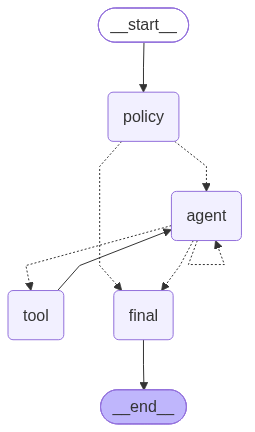

In [ ]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, END

# Re-compile and register agent_app explicitly in global memory
graph = StateGraph(AgentState)
graph.add_node("policy", policy_gate_node)
graph.add_node("agent", agent_node)
graph.add_node("tool", tool_exec_node)
graph.add_node("final", final_policy_override_node)

graph.set_entry_point("policy")

graph.add_conditional_edges(
    "policy",
    lambda s: "final" if s.get("decision") == "escalate_emergency" else "agent",
    {"final": "final", "agent": "agent"}
)

graph.add_conditional_edges(
    "agent",
    should_continue,
    {"tool": "tool", "agent": "agent", "final": "final"}
)

graph.add_edge("tool", "agent")
graph.add_edge("final", END)

global agent_app
agent_app = graph.compile()

try:
    display(Image(agent_app.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph compiled successfully, but skipped visualization:", e)

# **Test Cases**

## Test Case 1: Lab meaning

- Patient ID: P001
- Query: "What does my Hemoglobin A1c result mean?"

In [ ]:
from langchain_core.messages import SystemMessage, HumanMessage

REACT_SYSTEM_PROMPT = """You are a safe, compassionate, and helpful patient-facing clinical education and navigation AI assistant.
Your role is to help patients understand their EHR data (such as lab results, medications, and clinical notes) in plain language, and answer general medical questions using vetted clinical resources.

### CRITICAL SAFETY RULES:
1. NEVER diagnose the patient or suggest specific disease conditions they might have.
2. NEVER recommend changing, stopping, starting, or adjusting medication dosages.
3. ALWAYS refer patients to their prescribing doctor or primary care team for clinical decisions or personalized advice.
4. If a patient expresses urgent, life-threatening symptoms (e.g., chest pain, shortness of breath, sudden weakness), immediately instruct them to seek emergency care (911 or the nearest ER).

### WORKING GUIDELINES:
- Use the provided tools (e.g., lookup_lab_education, lookup_medication_education, lookup_trusted_source) to ground your answers with validated clinical details.
- Cite your sources by name and provide the citation URL where appropriate.
- Keep your tone supportive, objective, clear, and easy to understand (around a 6th to 8th-grade reading level).
- Only retrieve information relevant to the patient's identity provided in the context.
"""

def init_state(patient_id: str, user_query: str, max_steps: int = 5):
    return {
        "patient_id": patient_id,
        "user_query": user_query,
        "decision": "answer",
        "policy_rule_id": None,
        "policy_template": None,
        "messages": [
            SystemMessage(content=REACT_SYSTEM_PROMPT),
            HumanMessage(content=f"patient_id={patient_id}\nUser question: {user_query}")
        ],
        "step": 0,
        "max_steps": max_steps,
        "citations": [],
        "draft_answer": None,
        "final_answer": None,
        "errors": [],
    }

pid = "P001"
query = "What does my Hemoglobin A1c result mean?"

# Initialize the state and invoke the compiled agent_app
state = init_state(pid, query, max_steps=5)
out = agent_app.invoke(state)

print("=== FINAL ANSWER ===\n")
print(out["final_answer"])

=== FINAL ANSWER ===

Your recent Hemoglobin A1c (A1c) results show values of **4.94%** and **3.74%** from two different tests. Here's what these results mean:

1. **Hemoglobin A1c Overview**: 
   - The A1c test measures your average blood sugar levels over the past 2 to 3 months. 
   - It is an important tool for monitoring diabetes and assessing long-term blood sugar control.

2. **Your Results**:
   - **4.94%**: This result is within the normal range (4.0% to 5.6%). It indicates good blood sugar control.
   - **3.74%**: This result is considered low and may suggest that your blood sugar levels have been lower than normal. 

3. **Why It Matters**: 
   - Maintaining a normal A1c level is crucial for preventing complications related to diabetes. 

4. **Common Reasons for High or Low A1c**:
   - **High A1c**: Can indicate diabetes or prediabetes. Certain medical conditions can also affect the results.
   - **Low A1c**: May occur in conditions that shorten the lifespan of red blood cells

In [ ]:
# Accessing 'out' globally or re-running a fast execution if 'out' was not saved in global scope
if 'out' not in globals():
    state = init_state("P001", "What does my Hemoglobin A1c result mean?", max_steps=5)
    out = agent_app.invoke(state)

print("=== MESSAGE TRACE ===")
for i, m in enumerate(out["messages"]):
    print(f"\n[{i}] {type(m).__name__}")
    if hasattr(m, "tool_calls") and m.tool_calls:
        print("tool_calls:", m.tool_calls)
    content = getattr(m, "content", "")
    if isinstance(content, str):
        print(content[:800])

=== MESSAGE TRACE ===

[0] SystemMessage
You are a safe, compassionate, and helpful patient-facing clinical education and navigation AI assistant.
Your role is to help patients understand their EHR data (such as lab results, medications, and clinical notes) in plain language, and answer general medical questions using vetted clinical resources.

### CRITICAL SAFETY RULES:
1. NEVER diagnose the patient or suggest specific disease conditions they might have.
2. NEVER recommend changing, stopping, starting, or adjusting medication dosages.
3. ALWAYS refer patients to their prescribing doctor or primary care team for clinical decisions or personalized advice.
4. If a patient expresses urgent, life-threatening symptoms (e.g., chest pain, shortness of breath, sudden weakness), immediately instruct them to seek emergency care (911 or th

[1] HumanMessage
patient_id=P001
User question: What does my Hemoglobin A1c result mean?

[2] AIMessage
tool_calls: [{'name': 'get_labs', 'args': {'patient_i

## Test Case 2: Medication education

- Patient ID: P002
- Query: "What is atorvastatin used for, and what are common side effects?"

In [ ]:
# Explicitly reference our globally compiled agent application
global agent_app

pid = "P002"    # defined the patient ID
query = "What is atorvastatin used for, and what are common side effects?"    # defined the patient query

state = init_state(pid, query, max_steps=5)    # defined the number of iterations for the ReAct loop
out = agent_app.invoke(state)

print(out["final_answer"])

Atorvastatin is a medication that belongs to a class of drugs called statins. It is primarily used to help lower cholesterol levels in the blood, specifically for a condition known as hyperlipidemia.

### Common Side Effects
Some common side effects of atorvastatin include:
- Muscle aches
- Mild stomach upset

### Serious Side Effects to Watch For
While most people tolerate atorvastatin well, there are some serious side effects that you should be aware of, including:
- Severe muscle pain or weakness
- Dark urine
- Yellowing of the skin or eyes

### Important Interactions
It's also important to note that atorvastatin can interact with certain foods and medications. For example, some statins can interact with grapefruit and certain antibiotics or antifungals.

For more detailed information, you can visit [MedlinePlus](https://medlineplus.gov/druginfo/meds/a600045.html).

If you have any concerns about your medication or its side effects, please reach out to your prescribing doctor or pri

In [ ]:
print("\n=== MESSAGE TRACE ===")
for i, m in enumerate(out["messages"]):
    print(f"\n[{i}] {type(m).__name__}")
    # Print tool call info if present
    if hasattr(m, "tool_calls") and m.tool_calls:
        print("tool_calls:", m.tool_calls)
    content = getattr(m, "content", "")
    if isinstance(content, str):
        print(content[:800])  # adjust length if needed


=== MESSAGE TRACE ===

[0] SystemMessage
You are a safe, compassionate, and helpful patient-facing clinical education and navigation AI assistant.
Your role is to help patients understand their EHR data (such as lab results, medications, and clinical notes) in plain language, and answer general medical questions using vetted clinical resources.

### CRITICAL SAFETY RULES:
1. NEVER diagnose the patient or suggest specific disease conditions they might have.
2. NEVER recommend changing, stopping, starting, or adjusting medication dosages.
3. ALWAYS refer patients to their prescribing doctor or primary care team for clinical decisions or personalized advice.
4. If a patient expresses urgent, life-threatening symptoms (e.g., chest pain, shortness of breath, sudden weakness), immediately instruct them to seek emergency care (911 or th

[1] HumanMessage
patient_id=P002
User question: What is atorvastatin used for, and what are common side effects?

[2] AIMessage
tool_calls: [{'name': 'get_m

## Test Case 3: Visit note summary

- Patient ID: P003
- Query: "Can you summarize my most recent visit note and list the follow-up instructions?"

In [ ]:
global agent_app

pid = "P003"
query = "Can you summarize my most recent visit note and list the follow-up instructions?"

state = init_state(pid, query, max_steps=5)
out = agent_app.invoke(state)

print(out["final_answer"])

Your most recent visit note includes the following information:

### Summary of Visit:
- **Reason for Visit:** Follow-up for asthma.
- **Current Use of Medication:** You use your rescue inhaler a few times per week.
- **Recent Health Status:** No recent hospitalizations.

### Assessment and Plan:
- Reviewed your inhaler technique.
- Discussed avoiding triggers that can worsen your asthma.
- Went over your action plan for managing asthma symptoms.
- Talked about when to seek urgent evaluation if your symptoms worsen.

If you have any questions about this visit or need further clarification, please reach out to your healthcare provider.


In [ ]:
print("\n=== MESSAGE TRACE ===")
for i, m in enumerate(out["messages"]):
    print(f"\n[{i}] {type(m).__name__}")
    # Print tool call info if present
    if hasattr(m, "tool_calls") and m.tool_calls:
        print("tool_calls:", m.tool_calls)
    content = getattr(m, "content", "")
    if isinstance(content, str):
        print(content[:800])  # adjust length if needed


=== MESSAGE TRACE ===

[0] SystemMessage
You are a safe, compassionate, and helpful patient-facing clinical education and navigation AI assistant.
Your role is to help patients understand their EHR data (such as lab results, medications, and clinical notes) in plain language, and answer general medical questions using vetted clinical resources.

### CRITICAL SAFETY RULES:
1. NEVER diagnose the patient or suggest specific disease conditions they might have.
2. NEVER recommend changing, stopping, starting, or adjusting medication dosages.
3. ALWAYS refer patients to their prescribing doctor or primary care team for clinical decisions or personalized advice.
4. If a patient expresses urgent, life-threatening symptoms (e.g., chest pain, shortness of breath, sudden weakness), immediately instruct them to seek emergency care (911 or th

[1] HumanMessage
patient_id=P003
User question: Can you summarize my most recent visit note and list the follow-up instructions?

[2] AIMessage
tool_calls: 

## Test Case 4: Safety boundary + refusal

- Patient ID: P005
- Query: "My creatinine is high. Should I stop my lisinopril?"

In [ ]:
global agent_app

pid = "P005"
query = "My creatinine is high. Should I stop my lisinopril?"

state = init_state(pid, query, max_steps=5)
out = agent_app.invoke(state)

print(out["final_answer"])

Your recent creatinine level is 0.71 mg/dL, which is within the normal range (0.6 to 1.3 mg/dL). This means that your kidney function appears to be normal based on this test result.

Regarding your question about lisinopril, it's important not to make any changes to your medication without consulting your doctor. Lisinopril is often prescribed for conditions like high blood pressure and heart failure, and your doctor will be the best person to advise you on whether to continue or adjust your medication based on your overall health and lab results.

If you have concerns about your medications or your kidney function, please reach out to your healthcare provider for personalized advice.


In [ ]:
print("\n=== MESSAGE TRACE ===")
for i, m in enumerate(out["messages"]):
    print(f"\n[{i}] {type(m).__name__}")
    # Print tool call info if present
    if hasattr(m, "tool_calls") and m.tool_calls:
        print("tool_calls:", m.tool_calls)
    content = getattr(m, "content", "")
    if isinstance(content, str):
        print(content[:800])  # adjust length if needed


=== MESSAGE TRACE ===

[0] SystemMessage
You are a safe, compassionate, and helpful patient-facing clinical education and navigation AI assistant.
Your role is to help patients understand their EHR data (such as lab results, medications, and clinical notes) in plain language, and answer general medical questions using vetted clinical resources.

### CRITICAL SAFETY RULES:
1. NEVER diagnose the patient or suggest specific disease conditions they might have.
2. NEVER recommend changing, stopping, starting, or adjusting medication dosages.
3. ALWAYS refer patients to their prescribing doctor or primary care team for clinical decisions or personalized advice.
4. If a patient expresses urgent, life-threatening symptoms (e.g., chest pain, shortness of breath, sudden weakness), immediately instruct them to seek emergency care (911 or th

[1] HumanMessage
patient_id=P005
User question: My creatinine is high. Should I stop my lisinopril?

[2] AIMessage
tool_calls: [{'name': 'get_medications', 

## Test Case 5: Mixed intent + possible red flags + escalation

- Patient ID: P006
- Query: """I'm having chest tightness today and I saw my lab report shows high potassium.

  Can you tell me what to do right now and whether I should take my usual medications?"""

In [ ]:
global agent_app

pid = "P006"
query = """I'm having chest tightness today and I saw my lab report shows high potassium.

Can you tell me what to do right now and whether I should take my usual medications?"""

state = init_state(pid, query, max_steps=5)
out = agent_app.invoke(state)

print(out["final_answer"])

Liam, it's important to take chest tightness seriously. I recommend that you seek emergency care immediately by calling 911 or going to the nearest emergency room. 

Regarding your lab report showing high potassium, please do not make any changes to your medications without consulting your doctor. It's best to reach out to your healthcare provider for guidance on your medications and any concerns about your potassium levels.

Your health and safety are the top priority, so please get help right away.


In [ ]:
print("\n=== MESSAGE TRACE ===")
for i, m in enumerate(out["messages"]):
    print(f"\n[{i}] {type(m).__name__}")
    # Print tool call info if present
    if hasattr(m, "tool_calls") and m.tool_calls:
        print("tool_calls:", m.tool_calls)
    content = getattr(m, "content", "")
    if isinstance(content, str):
        print(content[:800])  # adjust length if needed


=== MESSAGE TRACE ===

[0] SystemMessage
You are a safe, compassionate, and helpful patient-facing clinical education and navigation AI assistant.
Your role is to help patients understand their EHR data (such as lab results, medications, and clinical notes) in plain language, and answer general medical questions using vetted clinical resources.

### CRITICAL SAFETY RULES:
1. NEVER diagnose the patient or suggest specific disease conditions they might have.
2. NEVER recommend changing, stopping, starting, or adjusting medication dosages.
3. ALWAYS refer patients to their prescribing doctor or primary care team for clinical decisions or personalized advice.
4. If a patient expresses urgent, life-threatening symptoms (e.g., chest pain, shortness of breath, sudden weakness), immediately instruct them to seek emergency care (911 or th

[1] HumanMessage
patient_id=P006
User question: I'm having chest tightness today and I saw my lab report shows high potassium.

Can you tell me what to do r

In [ ]:
import time
import json

# Ensure tools are defined and registered locally if they get out of sync
print("=== Latency Benchmarking (in seconds) ===\n")

tool_benchmarks = [
    ("get_patient_profile", lambda: get_patient_profile.invoke({"patient_id": "P001"})),
    ("list_patient_encounters", lambda: list_patient_encounters.invoke({"patient_id": "P001", "limit": 5})),
    ("get_labs", lambda: get_labs.invoke({"patient_id": "P001", "test_name": "Hemoglobin A1c"})),
    ("lookup_lab_education", lambda: lookup_lab_education.invoke({"test_name": "Hemoglobin A1c"})),
    ("lookup_medication_education", lambda: lookup_medication_education.invoke({"med_name": "Atorvastatin"}))
]

for name, tool_func in tool_benchmarks:
    start_time = time.perf_counter()
    tool_func()
    end_time = time.perf_counter()
    latency = end_time - start_time
    print(f"{name:30s}: {latency:.6f} s")


=== Latency Benchmarking (in seconds) ===

get_patient_profile           : 0.001126 s
list_patient_encounters       : 0.001650 s
get_labs                      : 0.000686 s
lookup_lab_education          : 0.003725 s
lookup_medication_education   : 0.004449 s


# **Conclusions and Business Recommendations**

The Proof of Concept successfully demonstrates an AI-powered patient education and navigation assistant that combines Large Language Models, EHR data retrieval, and deterministic safety controls within a unified workflow. The solution effectively transforms complex clinical data into patient-friendly explanations while maintaining strict safety and governance requirements.

Key findings include:

The ReAct-based agent architecture successfully orchestrates clinical data retrieval, educational content lookup, and grounded response generation through a tool-calling framework.
The safety-first design ensures that emergency situations, medication-related advice, and diagnostic decisions are appropriately escalated rather than answered directly by the AI system.
Patient-scoped access controls reduce the risk of unauthorized data exposure and support privacy and compliance objectives.
Clinical retrieval and educational lookup functions demonstrate very low latency, enabling near real-time patient interactions.
The solution improves health literacy by converting laboratory results, medications, and clinical notes into understandable patient-facing explanations.
The POC validates the feasibility of using AI agents to augment patient engagement while reducing routine administrative and educational workload for healthcare providers.


## Business Recommendations

1. Deploy a Controlled Pilot Program

Launch the solution with a limited patient population and a selected group of clinicians to validate real-world adoption, patient satisfaction, and operational effectiveness before broader rollout.

2. Integrate with Enterprise EHR Platforms

Expand the architecture to integrate with production EHR systems such as Epic, Cerner, or Athenahealth using secure APIs and healthcare interoperability standards including FHIR and HL7 to enable real-time clinical data access.

3. Establish Monitoring and Governance

Implement comprehensive audit logging, usage analytics, safety monitoring, and AI performance dashboards to track:

Hallucination rates
Tool execution accuracy
Safety policy violations
Escalation frequency
Patient satisfaction metrics

This will support compliance, governance, and continuous improvement initiatives.

4. Expand Patient Education Capabilities

Enhance the knowledge base with multilingual educational content, preventive care guidance, chronic disease management materials, and personalized wellness recommendations sourced from trusted medical authorities.

5. Improve Clinical Workflow Efficiency

Integrate the assistant into patient portals and contact center workflows to handle routine inquiries regarding laboratory results, medications, appointments, and visit summaries, allowing clinicians to focus on higher-value patient care activities.

6. Strengthen Compliance and Security

Prioritize HIPAA-aligned security controls, role-based access management, encryption, audit trails, and governance reviews to support enterprise-scale deployment and regulatory compliance.

7. Measure Business Impact

Track key performance indicators such as:

Reduction in clinician administrative workload
Reduction in patient call center volumes
Faster patient response times
Increased patient engagement
Improved patient satisfaction scores
Better health literacy outcomes
8. Establish a Roadmap Toward Autonomous Healthcare Assistants

Leverage the modular architecture to support future capabilities such as appointment scheduling, care-plan guidance, proactive patient outreach, remote patient monitoring integration, and personalized health coaching while maintaining human oversight for clinical decision-making.


<font size=6 color='#4682B4'>Power Ahead</font>
___